# 12. 物理モデルを組み込んだ AI：スマホ画像の高画質化と、塑性変形した部品の復元

**セミナー対応章**：第5章（3）　｜　**推奨ランタイム**：Colab無料枠 T4 GPU　｜　**所要時間**：約60分

AI だけ（ブラックボックス）で復元すると、学習と違う条件で性能が落ちたり、ありもしない模様を描いたり（ハルシネーション）します。
劣化の仕組みが物理で分かっている場合は、**物理モデルを AI の中に組み込む** と、少ないデータで安定し、何をしたかを説明でき、ハルシネーションも抑えられます。

1. **スマホの小さなカメラの画像 → フルサイズ一眼の画質へ**：レンズのぼけ（回折＋収差）とセンサーのノイズ（光子のゆらぎ＋読み出し）の物理モデルを、
   チャートの撮影で測ったパラメータとともに AI の計算の中に入れる（Deep Unfolding）。機材が変わってもパラメータを入れ替えるだけで対応できる
2. **塑性変形した金属部品**：亀裂が開き、腕が曲がり、先端が伸びて戻らない変形を、時刻 t とともに進む過程として物理モデルで作り、
   拡散モデルの考え方で **逆過程（変形を少しずつ戻す）を AI に学習させる**。AI が出すのは物理モデルのパラメータだけで、模様は描かない

比べる手法：物理モデルだけ（AI なし）、AI だけ（画像から画像を直接作る CNN・U-Net）、inpaint

**関連する研究**
- K. Zhang et al., *Deep Unfolding Network for Image Super-Resolution*（USRNet）, CVPR 2020：ぼけ・ノイズの物理モデルと CNN を交互に繰り返す
- K. Zhang et al., *Plug-and-Play Image Restoration with Deep Denoiser Prior*（DPIR）, TPAMI 2021
- EMVA Standard 1288：イメージセンサーの特性（光子数・読み出しノイズ）の測り方（Photon Transfer 法）
- A. Bansal et al., *Cold Diffusion: Inverting Arbitrary Image Transforms Without Noise*, NeurIPS 2023：ノイズ以外の劣化（ぼけ・変形など）を順過程にした拡散モデル
- H. Chung et al., *Diffusion Posterior Sampling for General Noisy Inverse Problems*, ICLR 2023：拡散モデルの逆過程を物理モデル（観測の式）で誘導する
- T. L. Anderson, *Fracture Mechanics: Fundamentals and Applications*, CRC Press：亀裂の開口・先端の鈍化（塑性）
- M. Raissi et al., *Physics-informed neural networks*, J. Comput. Phys. 2019：偏微分方程式の残差を損失に入れて学習する（PINN）

画像：1. は Kodak 標準テスト画像（r0k.us/graphics/kodak/。学習 21 枚、評価 3 枚：05・08・21）、2. は合金の板（結晶粒・けがき線・穴）をコードで描いた画像

In [1]:
# ===== 共通セットアップ（このセルを最初に1回だけ実行してください） =====
import os, sys, subprocess, time, urllib.request

IN_COLAB = "google.colab" in sys.modules

def pip_install(*pkgs):
    """足りないライブラリを静かにインストールする（Colab用）"""
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)

if IN_COLAB:
    # Colabには torch / transformers / diffusers などが最初から入っています。
    # 不足分だけ追加します（1〜2分）。
    pip_install("spandrel", "lpips", "diffusers>=0.30", "accelerate", "peft")

import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
print(f"実行環境: {'Google Colab' if IN_COLAB else 'ローカルPC'} / torch {torch.__version__}")
if DEVICE == "cuda":
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name}  VRAM: {p.total_memory / 1024**3:.1f} GB")
else:
    print("GPUが見つかりません。Colabでは［ランタイム］→［ランタイムのタイプを変更］→ T4 GPU を選んでください。")

WEIGHTS_DIR = os.path.abspath("weights")
os.makedirs(WEIGHTS_DIR, exist_ok=True)

def download(url, name=None):
    """学習済み重みをダウンロード（2回目以降はキャッシュを使う）"""
    path = os.path.join(WEIGHTS_DIR, name or url.split("/")[-1])
    if not os.path.exists(path):
        print("downloading", url)
        urllib.request.urlretrieve(url, path + ".part")      # 途中で止めても壊れたファイルが残らないように
        os.replace(path + ".part", path)
    return path

def load_sample(name="astronaut", size=None):
    """scikit-image同梱のサンプル画像（ネット不要）。name: astronaut / coffee / chelsea / rocket"""
    from skimage import data
    img = Image.fromarray(getattr(data, name)()).convert("RGB")
    if size:
        img = img.resize((size, size) if isinstance(size, int) else size, Image.BICUBIC)
    return img

def load_portrait():
    """顔が大きく写った 512x512 の高画質画像（Kodak 標準テスト画像 kodim04 の上部を切り出し）。
    Kodak 画像は画像処理の評価用に広く使われているフリーのテスト画像（r0k.us/graphics/kodak/）。
    ダウンロードできない場合は astronaut で代用。"""
    try:
        img = Image.open(download("https://r0k.us/graphics/kodak/kodak/kodim04.png")).convert("RGB")
        return img.crop((0, 160, 512, 672))
    except Exception as e:
        print("kodim04 を取得できなかったため astronaut を使います:", e)
        return load_sample("astronaut")

def to_np(img):
    """PIL → float32 [0,1] の (H,W,3) 配列"""
    return np.asarray(img.convert("RGB"), dtype=np.float32) / 255.0

def to_pil(arr):
    return Image.fromarray((np.clip(arr, 0, 1) * 255 + 0.5).astype(np.uint8))

def to_tensor(img):
    """PIL / ndarray → (1,3,H,W) テンソル"""
    a = to_np(img) if isinstance(img, Image.Image) else img
    return torch.from_numpy(np.ascontiguousarray(a, dtype=np.float32)).permute(2, 0, 1)[None].contiguous()

def tensor_to_pil(t):
    return to_pil(t[0].detach().float().clamp(0, 1).permute(1, 2, 0).cpu().numpy())

def psnr(a, b):
    a, b = to_np(a) if isinstance(a, Image.Image) else a, to_np(b) if isinstance(b, Image.Image) else b
    return 10 * np.log10(1.0 / np.mean((a - b) ** 2))

def ssim(a, b):
    from skimage.metrics import structural_similarity
    a, b = to_np(a) if isinstance(a, Image.Image) else a, to_np(b) if isinstance(b, Image.Image) else b
    return structural_similarity(a, b, channel_axis=2, data_range=1.0)

def show(images, titles=None, size=4, rows=1):
    """画像を横に並べて表示（タイトルは文字化け防止のため英数字推奨）"""
    n = len(images)
    cols = (n + rows - 1) // rows
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < n:
            im = images[i]
            if isinstance(im, np.ndarray) and im.ndim == 2:
                ax.imshow(im, cmap="gray")                      # 2次元配列（マップ・スペクトル）は自動スケール
            else:
                if isinstance(im, np.ndarray) and im.dtype != np.uint8:
                    im = np.clip(im, 0, 1)                      # float 画像は 0〜1 に収める
                ax.imshow(im)
            if titles:
                ax.set_title(titles[i], fontsize=11)
    plt.tight_layout()
    plt.show()

def gpu_mem():
    if DEVICE == "cuda":
        print(f"GPUメモリ使用量(ピーク): {torch.cuda.max_memory_allocated() / 1024**3:.2f} GB")

実行環境: ローカルPC / torch 2.11.0+cu128
GPU: NVIDIA GeForce RTX 5090 Laptop GPU  VRAM: 23.9 GB


In [2]:
import cv2
import torch.nn as nn
import torch.nn.functional as F
KODAK = "https://r0k.us/graphics/kodak/kodak/kodim{:02d}.png"
load = lambda n: to_np(Image.open(download(KODAK.format(n))))
TESTS = [5, 8, 21]
TRAIN = [n for n in range(1, 25) if n not in TESTS]
imgs = {n: load(n) for n in range(1, 25)}
P = lambda a, g: psnr(np.clip(a, 0, 1), g)
print("学習", len(TRAIN), "枚 / 評価", TESTS)

class SmallCNN(nn.Module):                                   # ブラックボックス：画像 → 画像（12 層）
    def __init__(self, ch=64, n=12):
        super().__init__()
        layers = [nn.Conv2d(3, ch, 3, padding=1), nn.ReLU()]
        for _ in range(n - 2):
            layers += [nn.Conv2d(ch, ch, 3, padding=1), nn.ReLU()]
        self.net = nn.Sequential(*layers, nn.Conv2d(ch, 3, 3, padding=1))
    def forward(self, x):
        return x + self.net(x)

def run_cnn(net, y):
    with torch.no_grad():
        return net(torch.from_numpy(y).permute(2, 0, 1)[None].to(DEVICE))[0].permute(1, 2, 0).cpu().numpy()

学習 21 枚 / 評価 [5, 8, 21]


## 1. スマホの小さなカメラの画像 → フルサイズ一眼の画質へ：機材の物理モデルを AI に組み込む
### 劣化モデル（スマホのカメラの物理）
一眼で撮った画像（正解 x）は、スマホで撮ると次の式のように劣化する：

**y = Q₈( Γ( k ∗ x + n ) )**　（内側から順に：ぼける → ノイズが乗る → ガンマ補正 → 8 ビット化）

| 記号 | 意味 |
|---|---|
| x | 一眼の画像（正解）。光の強さ（リニア） |
| k ∗ x | レンズのぼけ。k は点像分布関数 PSF（1 点の光がどう広がるか）、∗ は畳み込み |
| n | センサーのノイズ。平均 0、分散 (k∗x)/Φ + (σ_r/Φ)²（明るい所ほど大きい） |
| Γ | ガンマ補正（光の強さ → 画像の値。暗い所を持ち上げる） |
| Q₈ | 8 ビット化（256 段階に丸める） |
| y | スマホの画像 |

1. **レンズのぼけ** k ∗ x
   - 回折：レンズの口径が小さいと、光の波の広がり（Airy パターン）が画素より大きくなる。第 1 暗環の半径 = 1.22·λ·N（λ：光の波長 0.55 µm、N：F 値）
   - 収差：小さなレンズの誤差によるぼけ。標準偏差 σ_ab（画素）のガウスで近似
2. **センサーのノイズ**：画素に届く光子の数は画素の面積に比例する。白の所に届く光子（電子）の数を Φ とすると
   - 光子の数のゆらぎ（ショットノイズ、Poisson 分布）＋ 読み出し回路のノイズ（標準偏差 σ_r 電子）
   - 明るさ μ（0〜1）の画素の分散：**σ²(μ) = μ/Φ + (σ_r/Φ)²**
3. **画像処理**：ガンマ補正 Γ（sRGB）と 8 ビット化 Q₈

**逆の処理（y から x を求める）**：① Q₈ の丸めは小さいので無視 ② Γ⁻¹ で光の強さに戻す → k∗x + n
③ k と n を取り除く。ここが難しい：ぼけだけを割り算で戻す（逆フィルタ）とノイズが何倍にも増え、ノイズだけを除くとぼけが残る
→ 「ぼけを戻す（物理の式）」と「ノイズを除く（CNN）」を交互に少しずつ行う（下の Deep Unfolding）

フルサイズ一眼（画素ピッチ 6 µm）は画素の面積がスマホ（1 µm）の 36 倍 → 光子は 36 倍でノイズは約 1/6、回折のぼけも画素より小さい → ここでは正解 x とみなす

| パラメータ | 意味 | 何を材料に決めるか |
|---|---|---|
| N, p | F 値、画素ピッチ（µm） | カメラの仕様（カタログ値） |
| σ_ab | 収差のぼけ（画素） | **白黒の境界（エッジチャート）を撮影** し、境界のぼけ方に合わせる |
| Φ, σ_r | 白での光子数、読み出しノイズ | **一様な灰色チャートを明るさを変えて撮影**（RAW）し、平均と分散の直線の傾き 1/Φ と切片 (σ_r/Φ)² から求める（Photon Transfer 法、EMVA 1288 規格） |

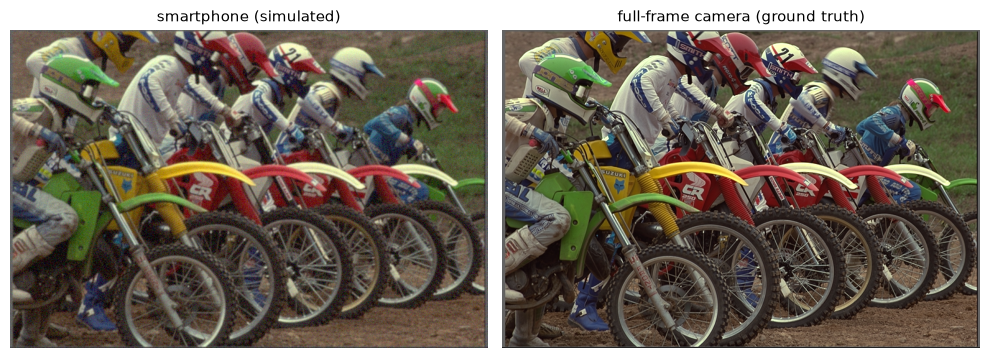

In [3]:
from scipy.special import j1
lin = lambda x: np.where(x <= 0.04045, x / 12.92, ((x + 0.055) / 1.055) ** 2.4).astype(np.float32)
srgb = lambda x: np.where(x <= 0.0031308, 12.92 * x, 1.055 * np.clip(x, 0, None) ** (1 / 2.4) - 0.055).astype(np.float32)
LAM = 0.55                                                            # 光の波長（µm、緑）

def psf_of(cam, size=21, ss=4):
    """回折（Airy パターン）に収差（ガウス）を重ねた PSF"""
    c = (np.arange(size * ss) - (size * ss - 1) / 2) / ss                 # 画素の 1/4 の細かさの座標
    v = np.pi * np.hypot(*np.meshgrid(c, c)) * cam["p"] / (LAM * cam["N"]) + 1e-9
    k = ((2 * j1(v) / v) ** 2).reshape(size, ss, size, ss).sum((1, 3))  # 画素の面積で積分
    k = cv2.GaussianBlur(k, (0, 0), cam["sig_ab"], borderType=cv2.BORDER_CONSTANT)
    return (k / k.sum()).astype(np.float32)

def phone_shot(x, cam, rng, raw=False):
    """スマホで撮る：レンズのぼけ → 光子のゆらぎ＋読み出しノイズ →（raw=False なら）ガンマ補正・8 ビット"""
    b = cv2.filter2D(lin(x), -1, psf_of(cam), borderType=cv2.BORDER_REFLECT)
    y = ((rng.poisson(np.clip(b, 0, None) * cam["phi"]) + rng.normal(0, cam["sr"], b.shape)) / cam["phi"]).astype(np.float32)
    return y if raw else (np.round(np.clip(srgb(y), 0, 1) * 255) / 255).astype(np.float32)

PHONE = dict(N=1.8, p=1.0, sig_ab=0.8, phi=300, sr=3.0)                # 想定するスマホ（暗めの室内）
PHONE2 = dict(N=2.4, p=0.8, sig_ab=1.3, phi=120, sr=3.0)               # 別のスマホ（学習の範囲外：小さい画素・暗い）
rng1 = np.random.default_rng(0)
x_ex = imgs[5]
show([phone_shot(x_ex, PHONE, rng1), x_ex], ["smartphone (simulated)", "full-frame camera (ground truth)"], size=5)

### パラメータを測る：灰色チャートとエッジチャートを撮影する
実物のスマホでも同じ手順で測れます（ここでは上のモデルで撮影を模擬し、測った値と設定値を比べます）。

スマホ 1: 収差 σ_ab 0.80（設定 0.8）, 光子数 Φ 300（設定 300）, 読み出し σ_r 3.1（設定 3.0）
スマホ 2: 収差 σ_ab 1.30（設定 1.3）, 光子数 Φ 119（設定 120）, 読み出し σ_r 3.0（設定 3.0）


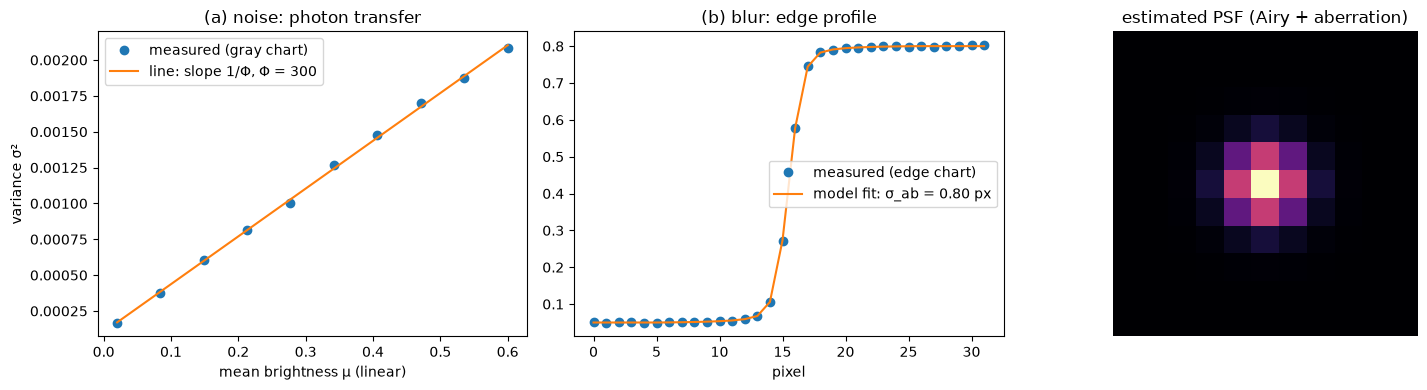

In [4]:
def calibrate(cam, rng):
    # (a) 一様な灰色チャートを明るさ 10 段階で RAW 撮影 → 平均と分散の直線（Photon Transfer）
    mu, var = [], []
    for lv in np.linspace(0.02, 0.6, 10):
        y = phone_shot(np.full((64, 64, 3), srgb(np.float32(lv)), np.float32), cam, rng, raw=True)
        mu.append(y.mean()); var.append(y.var())
    a, b = np.polyfit(mu, var, 1)
    phi = 1 / a; sr = np.sqrt(max(b, 0)) * phi
    # (b) 白黒の境界（エッジチャート）を 20 回撮影して平均 → 境界の明るさの変化に、PSF のモデルを合わせる
    edge = np.full((64, 64, 3), srgb(np.float32(0.05)), np.float32); edge[:, 32:] = srgb(np.float32(0.8))
    prof = np.mean([phone_shot(edge, cam, rng, raw=True)[..., 1].mean(0) for _ in range(20)], 0)
    def model(s):
        k = psf_of(dict(cam, sig_ab=s))
        return cv2.filter2D(lin(edge)[..., 1], -1, k, borderType=cv2.BORDER_REFLECT).mean(0)
    grid = np.arange(0.2, 2.0, 0.02)
    sig = grid[np.argmin([np.sum((model(s) - prof)[16:48] ** 2) for s in grid])]
    return dict(N=cam["N"], p=cam["p"], sig_ab=sig, phi=phi, sr=sr), (mu, var, a, b), (prof, model(sig))

est1, ptc1, edge1 = calibrate(PHONE, rng1)
est2, ptc2, edge2 = calibrate(PHONE2, rng1)
for name, c, e in [("スマホ 1", PHONE, est1), ("スマホ 2", PHONE2, est2)]:
    print(f"{name}: 収差 σ_ab {e['sig_ab']:.2f}（設定 {c['sig_ab']}）, 光子数 Φ {e['phi']:.0f}（設定 {c['phi']}）, 読み出し σ_r {e['sr']:.1f}（設定 {c['sr']}）")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
mu, var, a, b = ptc1
ax[0].plot(mu, var, "o", label="measured (gray chart)"); ax[0].plot(mu, np.polyval([a, b], mu), "-", label=f"line: slope 1/Φ, Φ = {1/a:.0f}")
ax[0].set_xlabel("mean brightness μ (linear)"); ax[0].set_ylabel("variance σ²"); ax[0].set_title("(a) noise: photon transfer"); ax[0].legend()
ax[1].plot(edge1[0][16:48], "o", label="measured (edge chart)"); ax[1].plot(edge1[1][16:48], "-", label=f"model fit: σ_ab = {est1['sig_ab']:.2f} px")
ax[1].set_xlabel("pixel"); ax[1].set_title("(b) blur: edge profile"); ax[1].legend()
ax[2].imshow(psf_of(est1)[5:16, 5:16], cmap="magma"); ax[2].set_title("estimated PSF (Airy + aberration)"); ax[2].axis("off")
plt.tight_layout(); plt.show()

### 3 つの方法を比べる
- **物理モデルだけ（AI なし）**：測った PSF とノイズで Wiener フィルタ。ぼけは戻るがノイズが増える
- **AI だけ（ブラックボックス CNN）**：スマホ画像 → 一眼画像 を直接学習（学習データは物理モデルで作る）
- **物理モデルを組み込んだ AI（Deep Unfolding）**：Γ⁻¹ で光の強さに戻した y から始め、次の ①② を 4 回交互に繰り返す
  - ① 物理の式（ぼけを戻す）：**x = argmin ‖k∗x − y‖² + α‖x − z‖²**。ぼかし直すと観測 y に一致し、かつ直前の CNN の結果 z に近い画像を求める。
    フーリエ変換で一発で解ける。α が大きいほど z を信じ、小さいほど観測 y を信じる
  - ② CNN（ノイズを除く）：**z = DRUNet(x, σ)**。DRUNet は大量の画像で学習済みのノイズ除去 CNN（演習 05 の DPIR と同じ）。
    σ は物理モデル σ(μ) = √(μ/Φ + (σ_r/Φ)²) で計算した「ノイズの量の地図」。DRUNet は sRGB の画像で学習されているので、x を sRGB に直して入れる
  - **学習するもの**：DRUNet の係数（約 3,200 万個。学習済みの値から小さな学習率で調整）、各回の α（4 個）、地図の倍率（4 個）。
    **学習しないもの**：PSF k・Φ・σ_r（チャートで測って入力する）→ 機材が変わっても入れ替えるだけで再学習は不要
  - 損失：最終出力と一眼の画像（正解）の差（L1）。①があるので、観測と矛盾する模様を作りにくい（ハルシネーションの抑制）
- 学習：Kodak 21 枚の切り出し。いろいろなスマホ（F 値 1.6〜2.0、収差 0.5〜1.1、光子数 200〜600）を物理モデルで模擬。評価：3 枚 × 2 台（スマホ 2 は学習の範囲外）

In [5]:
def rand_cam(rng):
    return dict(N=rng.uniform(1.6, 2.0), p=rng.uniform(0.9, 1.1), sig_ab=rng.uniform(0.5, 1.1), phi=rng.uniform(200, 600), sr=3.0)

PZ, M = 96, 12
rngp = np.random.default_rng(1)
def make_sample():
    x = imgs[rngp.choice(TRAIN)]; H, W = x.shape[:2]
    y0, x0 = rngp.integers(0, H - PZ - 2 * M), rngp.integers(0, W - PZ - 2 * M)
    xc = x[y0:y0 + PZ + 2 * M, x0:x0 + PZ + 2 * M]; cam = rand_cam(rngp)
    y = phone_shot(xc, cam, rngp)[M:-M, M:-M]
    return y, xc[M:-M, M:-M], psf_of(cam), cam["phi"], cam["sr"]
t0 = time.time()
pool = [make_sample() for _ in range(6000)]                          # 物理モデルで作った学習データ
to_t = lambda a: torch.from_numpy(np.stack(a)).to(DEVICE)
Yp, Xp = to_t([s[0] for s in pool]).permute(0, 3, 1, 2), to_t([s[1] for s in pool]).permute(0, 3, 1, 2)
Kp, PHIp, SRp = to_t([s[2] for s in pool])[:, None], to_t([np.float32(s[3]) for s in pool]), to_t([np.float32(s[4]) for s in pool])
print(f"学習データ {len(pool)} 組を作成 {time.time()-t0:.0f}s")

def lin_t(x): return torch.where(x <= 0.04045, x / 12.92, ((x + 0.055) / 1.055) ** 2.4)
def srgb_t(x): return torch.where(x <= 0.0031308, 12.92 * x, 1.055 * x.clamp(min=1e-8) ** (1 / 2.4) - 0.055)

def psf2otf(k, H, W):
    """PSF をフーリエ変換（中心を原点に移す）"""
    kp = torch.zeros(k.shape[0], 1, H, W, device=k.device); s = k.shape[-1]
    kp[..., :s, :s] = k
    return torch.fft.fft2(torch.roll(kp, (-(s // 2), -(s // 2)), (2, 3)))

import spandrel
DRUNET_URL = "https://github.com/cszn/KAIR/releases/download/v1.0/drunet_color.pth"   # 演習 05 と同じ学習済みの重み

class Unfolding(nn.Module):
    """物理モデルを組み込んだ AI：物理の式（PSF でぼかし直すと観測に一致）と DRUNet（学習済みのノイズ除去）を交互に K 回"""
    def __init__(self, K=4):
        super().__init__()
        self.den = spandrel.ModelLoader().load_from_file(download(DRUNET_URL)).model
        self.a = nn.Parameter(torch.zeros(K)); self.b = nn.Parameter(torch.zeros(K)); self.K = K
    def forward(self, y8, k, phi, sr, pad=16):
        y = lin_t(y8)                                                # 光の強さ（リニア）に戻す
        sig2 = y.clamp(min=0).mean(1, keepdim=True) / phi[:, None, None, None] + (sr / phi)[:, None, None, None] ** 2   # ノイズの量（物理モデル）
        yp = F.pad(y, (pad,) * 4, mode="reflect"); H, W = yp.shape[-2:]
        Kf = psf2otf(k, H, W); Yf = torch.fft.fft2(yp)
        z = y
        for i in range(self.K):
            al = F.softplus(self.a[i]) * sig2.mean((1, 2, 3), keepdim=True) * 50
            Zf = torch.fft.fft2(F.pad(z, (pad,) * 4, mode="reflect"))
            x = torch.fft.ifft2((Kf.conj() * Yf + al * Zf) / (Kf.abs() ** 2 + al)).real[..., pad:-pad, pad:-pad]   # 物理の式：観測に合わせる
            m = x.clamp(min=0).mean(1, keepdim=True).clamp(min=2e-3)
            slope = 1.055 / 2.4 * m ** (1 / 2.4 - 1)                                                             # ガンマの傾き
            smap = (sig2.sqrt() * slope * F.softplus(self.b[i]) / np.log(2)).clamp(0, 0.5)                      # sRGB でのノイズの量の地図
            z = lin_t(self.den(torch.cat([srgb_t(x.clamp(0, 1)), smap], 1)).clamp(0, 1))                       # DRUNet：ノイズを除く
        return srgb_t(z.clamp(0, 1))

def train_net(net, fwd, iters=3000):
    torch.manual_seed(0); t0 = time.time()
    if isinstance(net, Unfolding):                            # 学習済みの DRUNet は小さな学習率で少しだけ調整
        opt = torch.optim.Adam([dict(params=[net.a, net.b], lr=1e-2), dict(params=net.den.parameters(), lr=1e-5)])
    else:
        opt = torch.optim.Adam(net.parameters(), 2e-4)
    for it in range(iters):
        i = torch.randint(0, len(pool), (16,), device=DEVICE)
        loss = F.l1_loss(fwd(net, i), Xp[i]); opt.zero_grad(); loss.backward(); opt.step()
    print(f"{type(net).__name__}: {sum(p.numel() for p in net.parameters())/1e3:.0f}k パラメータ, 学習 {time.time()-t0:.0f}s")
    return net

unf = train_net(Unfolding().to(DEVICE), lambda n, i: n(Yp[i], Kp[i], PHIp[i], SRp[i]))
bb = train_net(SmallCNN().to(DEVICE), lambda n, i: n(Yp[i]))

学習データ 6000 組を作成 18s


Unfolding: 32641k パラメータ, 学習 1104s


SmallCNN: 373k パラメータ, 学習 72s


smartphone (input)           PSNR  スマホ 1：22.98 dB   スマホ 2（学習の範囲外）：19.51 dB
physics only (Wiener)        PSNR  スマホ 1：20.96 dB   スマホ 2（学習の範囲外）：21.41 dB
AI only (black-box CNN)      PSNR  スマホ 1：27.71 dB   スマホ 2（学習の範囲外）：22.67 dB
physics + AI (unfolding)     PSNR  スマホ 1：29.26 dB   スマホ 2（学習の範囲外）：24.32 dB


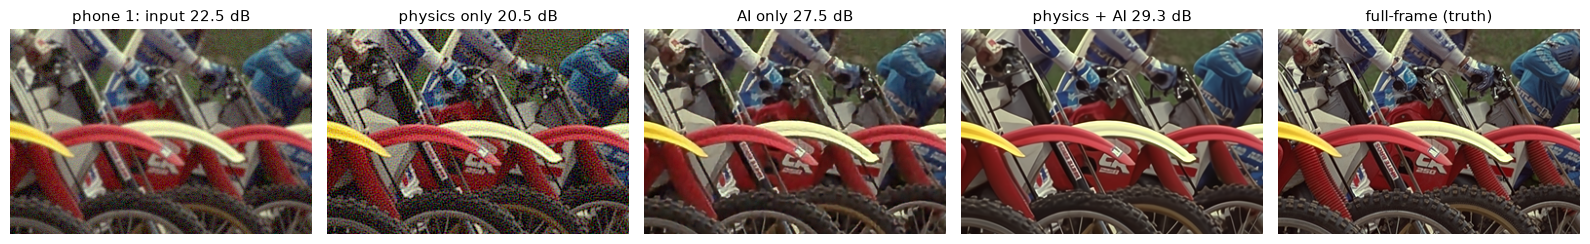

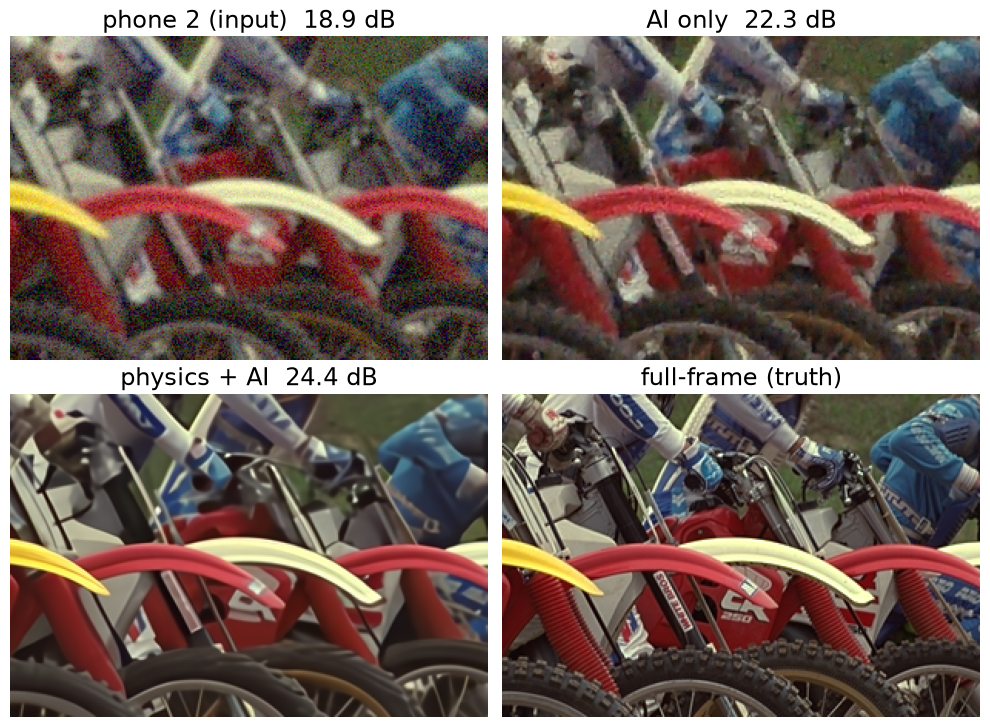

In [6]:
def wiener(y8, cam):
    """物理モデルだけ：測った PSF とノイズの量で Wiener フィルタ（AI なし）"""
    y = lin(y8); H, W = y.shape[:2]; pad = 16
    yp = np.pad(y, ((pad, pad), (pad, pad), (0, 0)), mode="reflect")
    Kf = psf2otf(torch.from_numpy(psf_of(cam))[None, None], *yp.shape[:2])[0, 0].cpu().numpy()
    nsr = (y.mean() / cam["phi"] + (cam["sr"] / cam["phi"]) ** 2) / np.var(y)
    out = np.stack([np.fft.ifft2(np.conj(Kf) * np.fft.fft2(yp[..., c]) / (np.abs(Kf) ** 2 + nsr)).real for c in range(3)], -1)
    return srgb(np.clip(out[pad:-pad, pad:-pad], 0, 1))

def run_unf(y8, cam):
    with torch.no_grad():
        t = lambda v: torch.tensor([np.float32(v)], device=DEVICE)
        o = unf(torch.from_numpy(y8).permute(2, 0, 1)[None].to(DEVICE), torch.from_numpy(psf_of(cam))[None, None].to(DEVICE), t(cam["phi"]), t(cam["sr"]))
    return o[0].permute(1, 2, 0).cpu().numpy()

names1 = ["smartphone (input)", "physics only (Wiener)", "AI only (black-box CNN)", "physics + AI (unfolding)"]
res1 = {c: {k: [] for k in names1} for c in ("phone 1", "phone 2")}
exs = {}
rng_e = np.random.default_rng(123)
for cname, cam, est in [("phone 1", PHONE, est1), ("phone 2", PHONE2, est2)]:
    for n in TESTS:
        y = phone_shot(imgs[n], cam, rng_e)
        outs = [y, wiener(y, est), run_cnn(bb, y), run_unf(y, est)]           # 物理モデルには「測った」パラメータを使う
        for k, o in zip(names1, outs):
            res1[cname][k].append(P(o, imgs[n]))
        if n == 5:
            exs[cname] = outs
for k in names1:
    print(f"{k:28s} PSNR  スマホ 1：{np.mean(res1['phone 1'][k]):5.2f} dB   スマホ 2（学習の範囲外）：{np.mean(res1['phone 2'][k]):5.2f} dB")
zoom = (slice(120, 330), slice(330, 640))
outs = exs["phone 1"]
show([o[zoom] for o in outs] + [imgs[5][zoom]],
     [f"phone 1: input {P(outs[0], imgs[5]):.1f} dB", f"physics only {P(outs[1], imgs[5]):.1f} dB", f"AI only {P(outs[2], imgs[5]):.1f} dB",
      f"physics + AI {P(outs[3], imgs[5]):.1f} dB", "full-frame (truth)"], size=3.2)
outs = exs["phone 2"]                                       # 学習の範囲外のスマホ 2：大きく表示
fig, ax = plt.subplots(2, 2, figsize=(10, 7.4))
for a, im, tt in zip(ax.flat, [outs[0], outs[2], outs[3], imgs[5]],
                     [f"phone 2 (input)  {P(outs[0], imgs[5]):.1f} dB", f"AI only  {P(outs[2], imgs[5]):.1f} dB",
                      f"physics + AI  {P(outs[3], imgs[5]):.1f} dB", "full-frame (truth)"]):
    a.imshow(np.clip(im[zoom], 0, 1)); a.set_title(tt, fontsize=17); a.axis("off")
plt.tight_layout(); plt.show()

**観察ポイント**：物理モデルだけ（Wiener）ではノイズが増え、AI だけ（ブラックボックス）は **学習したスマホと違う機材では性能が大きく落ちます**。
物理モデルを組み込んだ AI は、測ったパラメータ（PSF・光子数・読み出しノイズ）を入れ替えるだけで別のスマホにも対応でき、
「ぼかし直すと観測に一致する」という制約を毎回かけるので、観測と矛盾する模様を作りにくくなります。

## 2. 塑性変形した金属部品：変形の過程を学習して、逆にたどって戻す
### 劣化モデル（亀裂と塑性変形の物理）
合金の板が端から割れ、さらに力がかかり続けると、変形は時刻 t（0 → 1）とともに進む。
**x_t は「時刻 t まで変形が進んだ画像」**：x₀ が変形前の部品（復元したい画像）、x₁ が観測した画像、x_0.5 は変形が半分まで進んだ画像。
物理モデルを使えば、どの時刻の x_t でも計算できる。亀裂の先端を原点に、
前方からの角度 φ（亀裂の面が ±π）と先端からの距離 r で表すと：
1. **開口と曲げ**：亀裂の両側が回転して開く。回転角は **(t·θ/2)·(1 + β·r/R)** で、先端から遠いほど大きく回る（腕が曲がる＝直線が曲線になる）
2. **先端の鈍化（塑性）**：先端の後ろ側の材料が、先端から押し出されるように最大 **t·δ** 画素だけ伸びて戻らない → 先端が丸く開く
3. **不均一な塑性流れ**：結晶粒ごとに伸び方が違い、全体に滑らかなゆがみ（最大 **t·A** 画素）が残る

| パラメータ | 意味 |
|---|---|
| 先端の位置・亀裂の向き | どこから、どちらへ割れたか |
| θ | 開いた角度（4〜13 度） |
| β | 腕の曲がり（0 なら回転だけ） |
| δ | 先端の鈍化（0〜6 画素） |
| A | 不均一なゆがみの大きさ（0〜3 画素） |

パラメータが多く、場所ごとに違う（ゆがみ）ので、**すき間の形だけからは決められない**（亀裂の両側に 2 本の直線を当てはめるような単純な方法は使えない）。

### 拡散モデルとの対応：順過程と逆過程
|  | 拡散モデル（画像生成） | この演習（塑性変形） |
|---|---|---|
| 順過程（劣化を加える） | x₀ にノイズを少しずつ足す（式で計算） | x₀ を物理モデルで少しずつ変形させる（式で計算） |
| AI が学習すること | x_t に **足されたノイズ** を予測 | x_t に **加わった変形のパラメータ** を予測 |
| 逆過程の 1 ステップ | 予測したノイズを **式で引く** | 予測した変形の一部を **物理の式で戻す**（逆変形） |
| 学習データ | 画像 x₀ ＋ 乱数で選んだ t とノイズ | 変形前の部品 x₀ ＋ 乱数で選んだ t とパラメータ（物理モデルで x_t を作る） |

拡散モデルでも、AI が予測するのは「何が足されたか」（ノイズ）で、それを取り除くのは式です。
ここでは足されたものが「変形」なので、AI はそのパラメータを予測し、取り除くのは物理の式（逆変形）です（ノイズの代わりに別の劣化を使う拡散モデル：Cold Diffusion）。
AI は色や模様を描かず、画素は観測画像から持ってくる → ありもしない結晶粒を作らない（ハルシネーションの抑制）。最後に残った細い割れ目だけ inpaint

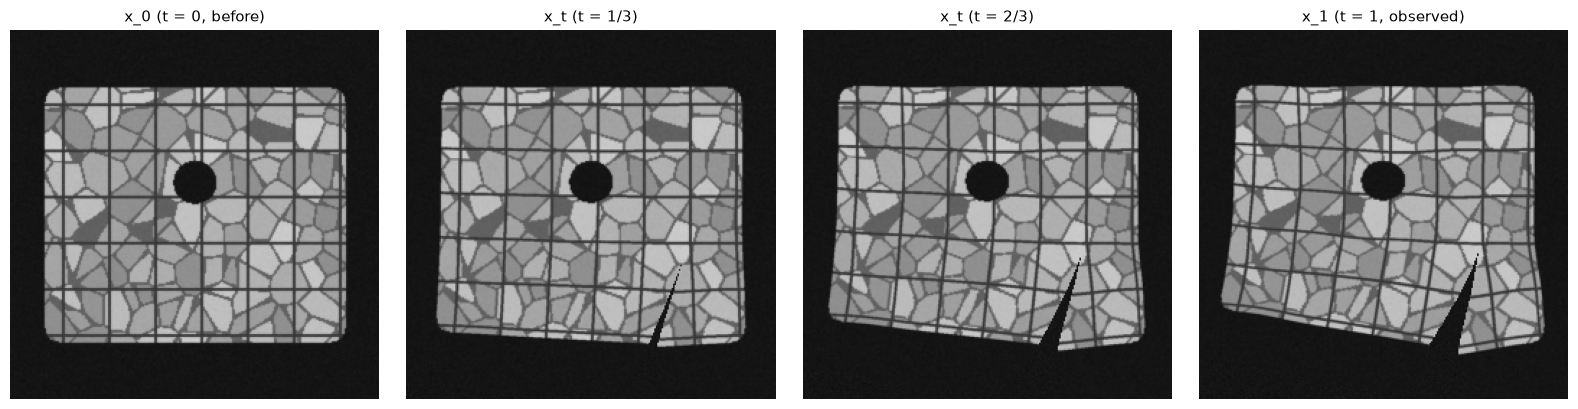

In [7]:
from scipy.spatial import cKDTree
from scipy import ndimage
S2 = 256                                                      # 画像の大きさ

def make_part(rng):
    """合金の板（結晶粒＋けがき線＋穴）を暗い背景の上に描く"""
    yy, xx = np.mgrid[0:S2, 0:S2].astype(np.float32)
    seeds = rng.uniform(0, S2, (160, 2))
    d, i = cKDTree(seeds).query(np.stack([xx.ravel(), yy.ravel()], 1), k=2)
    tone = rng.uniform(0.55, 0.80, 160)[i[:, 0]].reshape(S2, S2)                 # 結晶粒ごとに明るさが違う
    tone[(d[:, 1] - d[:, 0]).reshape(S2, S2) < 1.6] = 0.38                       # 粒界
    gx, gy = rng.uniform(0, 32, 2)
    tone[(np.abs((xx - gx) % 32 - 16) < 1.0) | (np.abs((yy - gy) % 32 - 16) < 1.0)] = 0.22   # けがき線（32 画素ごと）
    x0, y0, x1, y1 = 24, 40, 232, 216
    plate = np.zeros((S2, S2), np.uint8)
    cv2.rectangle(plate, (x0 + 10, y0), (x1 - 10, y1), 1, -1); cv2.rectangle(plate, (x0, y0 + 10), (x1, y1 - 10), 1, -1)
    for cx, cy in [(x0 + 10, y0 + 10), (x1 - 10, y0 + 10), (x0 + 10, y1 - 10), (x1 - 10, y1 - 10)]:
        cv2.circle(plate, (cx, cy), 10, 1, -1)                                   # 角の丸い板
    hc = rng.uniform([60, 80], [196, 176])
    plate[(xx - hc[0]) ** 2 + (yy - hc[1]) ** 2 < 15 ** 2] = 0                   # 穴
    img = np.where(plate > 0, tone, 0.08) + rng.normal(0, 0.01, (S2, S2))
    return np.repeat(np.clip(img, 0, 1)[..., None].astype(np.float32), 3, 2), hc

def rand_params(rng, hc):
    """亀裂と塑性変形のパラメータを乱数で決める"""
    while True:
        side = rng.integers(4); u = rng.uniform(70, 186)
        mouth, n_in = [(np.array([24.0, u]), np.array([1.0, 0])), (np.array([232.0, u]), np.array([-1.0, 0])),
                       (np.array([u, 40.0]), np.array([0, 1.0])), (np.array([u, 216.0]), np.array([0, -1.0]))][side]
        ang = np.arctan2(n_in[1], n_in[0]) + rng.uniform(-0.4, 0.4)
        tip = mouth + rng.uniform(70, 120) * np.array([np.cos(ang), np.sin(ang)])
        s = np.clip((hc - mouth) @ (tip - mouth) / np.sum((tip - mouth) ** 2), 0, 1)
        if np.linalg.norm(mouth + s * (tip - mouth) - hc) > 30:                  # 亀裂が穴を通らないようにする
            break
    field = cv2.resize(rng.normal(0, 1, (2, 8, 8)).transpose(1, 2, 0).astype(np.float32), (S2, S2), interpolation=cv2.INTER_CUBIC)
    return dict(tip=tip, a=ang + np.pi, theta=rng.uniform(0.08, 0.22), beta=rng.uniform(0, 1.5),
                delta=rng.uniform(0, 6), A=rng.uniform(0, 3), field=field / np.abs(field).max())

PHI0, R0, RHO = np.pi / 3, 150.0, 20.0
def deform_map(pr, t, ss=1):
    """物理モデル：変形前の各点 X が、時間 t でどこへ動くか（T_t(X)）。ss > 1 なら画素を ss×ss に細かく分けた点で計算"""
    c = ((np.arange(S2 * ss) + 0.5) / ss - 0.5).astype(np.float32)
    yy, xx = np.meshgrid(c, c, indexing="ij")
    dx, dy = xx - pr["tip"][0], yy - pr["tip"][1]
    r = np.hypot(dx, dy)
    phi = (np.arctan2(dy, dx) - (pr["a"] + np.pi) + np.pi) % (2 * np.pi) - np.pi          # 前方からの角度
    s = np.clip((np.abs(phi) - PHI0) / (np.pi - PHI0), 0, 1); w = s * s * (3 - 2 * s)     # 後ろ側ほど 1
    phi2 = phi - np.sign(phi) * w * t * pr["theta"] / 2 * (1 + pr["beta"] * r / R0)     # 1. 開口と曲げ
    r2 = r + w * t * pr["delta"] * (1 - np.exp(-r / RHO))                                 # 2. 先端の鈍化
    ang = phi2 + pr["a"] + np.pi
    mx, my = pr["tip"][0] + r2 * np.cos(ang), pr["tip"][1] + r2 * np.sin(ang)
    fd = cv2.resize(pr["field"], (S2 * ss, S2 * ss), interpolation=cv2.INTER_LINEAR) if ss > 1 else pr["field"]
    mx = mx + t * pr["A"] * fd[..., 0]; my = my + t * pr["A"] * fd[..., 1]                 # 3. 不均一なゆがみ
    return np.stack([mx, my], -1).astype(np.float32)

def render(x, pr, t, rng=None, ss=3):
    """変形前の画像 x の各点を物理モデルで動かして描く（画素を細かく分けて置き、何も届かなかった所＝すき間は暗い背景）"""
    Tf = deform_map(pr, t, ss)
    xf = cv2.resize(x, (S2 * ss, S2 * ss), interpolation=cv2.INTER_LINEAR)
    px, py = np.round(Tf[..., 0]).astype(int).ravel(), np.round(Tf[..., 1]).astype(int).ravel()
    ok = (px >= 0) & (px < S2) & (py >= 0) & (py < S2)
    idx = py[ok] * S2 + px[ok]
    wsum = np.bincount(idx, minlength=S2 * S2).reshape(S2, S2)
    out = np.stack([np.bincount(idx, xf[..., c].ravel()[ok], minlength=S2 * S2).reshape(S2, S2) for c in range(3)], -1)
    out = out / np.maximum(wsum, 1)[..., None]
    void = wsum == 0
    bgv = 0.08 + (rng.normal(0, 0.01, void.sum()) if rng is not None else 0)
    out[void] = np.asarray(bgv)[:, None] if rng is not None else 0.08
    return out.astype(np.float32), void

rng2 = np.random.default_rng(3)
x_ex, hc = make_part(rng2); pr_ex = rand_params(rng2, hc)
pr_ex.update(theta=0.18, beta=1.2, delta=5.0, A=2.5)                       # 例：見やすいように大きめの変形
steps = [render(x_ex, pr_ex, t, rng2)[0] for t in (0, 0.33, 0.67, 1.0)]
show(steps, ["x_0 (t = 0, before)", "x_t (t = 1/3)", "x_t (t = 2/3)", "x_1 (t = 1, observed)"], size=4)

### 学習：変形の過程（順過程）を物理モデルで作り、逆過程を AI に学ばせる
- 部品の画像（変形前）を 400 枚作っておき、学習の各回で **パラメータと時刻 t（0.1〜1）を乱数で選んで、GPU 上で変形させる**（毎回新しい学習データ）
- AI は、変形した画像から **物理モデルの 6 個の数**（先端の x・y、向き、開いた角度 t·θ、曲がり β、鈍化 t·δ）を出す。U-Net は画像（地図）を出すので、
  **U-Net で 6 枚の地図を出し、そこから数を読む**：
  1. 入力：変形した画像（半分の大きさ）＋各画素の座標（2 枚）
  2. U-Net の出力：1 枚目は「先端らしさ」の地図、2〜6 枚目は向き（cos・sin）・角度・曲がり・鈍化を表す地図
  3. 先端の位置＝「先端らしさ」を重みとした画素の座標の **重心**。残りの 5 個＝2〜6 枚目の地図を、先端らしさの重みで **平均** した値
  4. 6 個の数から、物理の式で変位場を計算する（学習するのは U-Net の重みだけ）
- 損失：① パラメータから **物理の式で計算した変位場** と正解の変位場の差 ② パラメータそのものの差
- 比較用：画像 → 画像 を直接学習する U-Net（ブラックボックス、同じ方法で作ったデータ）

In [8]:
def deform_map_t(prs, t, ss=1):
    """deform_map の torch 版（複数の部品をまとめて GPU で計算）。返り値 (B, H·ss, W·ss, 2)"""
    c = (torch.arange(S2 * ss, device=DEVICE, dtype=torch.float32) + 0.5) / ss - 0.5
    yy, xx = torch.meshgrid(c, c, indexing="ij")
    g = lambda f: torch.tensor([f(p) for p in prs], device=DEVICE, dtype=torch.float32)[:, None, None]
    tx, ty, a = g(lambda p: p["tip"][0]), g(lambda p: p["tip"][1]), g(lambda p: p["a"])
    th, be, de, A = g(lambda p: p["theta"]), g(lambda p: p["beta"]), g(lambda p: p["delta"]), g(lambda p: p["A"])
    t = t[:, None, None]
    dx, dy = xx[None] - tx, yy[None] - ty
    r = torch.hypot(dx, dy)
    phi = torch.remainder(torch.atan2(dy, dx) - (a + np.pi) + np.pi, 2 * np.pi) - np.pi
    s = ((phi.abs() - PHI0) / (np.pi - PHI0)).clamp(0, 1); w = s * s * (3 - 2 * s)
    phi2 = phi - torch.sign(phi) * w * t * th / 2 * (1 + be * r / R0)
    r2 = r + w * t * de * (1 - torch.exp(-r / RHO))
    ang = phi2 + a + np.pi
    fd = torch.from_numpy(np.stack([p["field"] for p in prs])).to(DEVICE).permute(0, 3, 1, 2)
    fd = F.interpolate(fd, size=(S2 * ss, S2 * ss), mode="bilinear", align_corners=False).permute(0, 2, 3, 1) if ss > 1 else fd.permute(0, 2, 3, 1)
    return torch.stack([tx + r2 * torch.cos(ang) + t * A * fd[..., 0], ty + r2 * torch.sin(ang) + t * A * fd[..., 1]], -1)

def render_t(x, T):
    """render の torch 版：x (B,3,H,W) を、細かい点ごとの移動先 T (B,2H,2W,2) へ置く"""
    B = x.shape[0]
    xf = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
    px, py = T[..., 0].round().long(), T[..., 1].round().long()
    ok = (px >= 0) & (px < S2) & (py >= 0) & (py < S2)
    idx = (torch.arange(B, device=DEVICE)[:, None, None] * S2 * S2 + py.clamp(0, S2 - 1) * S2 + px.clamp(0, S2 - 1))[ok]
    wsum = torch.zeros(B * S2 * S2, device=DEVICE).index_add_(0, idx, torch.ones_like(idx, dtype=torch.float32))
    out = torch.stack([torch.zeros(B * S2 * S2, device=DEVICE).index_add_(0, idx, xf[:, ch][ok]) for ch in range(3)], 1)
    out = out / wsum.clamp(min=1)[:, None]
    void = wsum == 0
    out[void] = 0.08 + 0.01 * torch.randn(int(void.sum()), 1, device=DEVICE)
    return out.view(B, S2, S2, 3).permute(0, 3, 1, 2)

t0 = time.time()
rng_b = np.random.default_rng(100)
bank = [make_part(rng_b) for _ in range(400)]                                 # 部品の画像（変形前）400 枚
Xb = torch.from_numpy(np.stack([b[0] for b in bank])).permute(0, 3, 1, 2).to(DEVICE)
GRID = np.stack(np.meshgrid(np.arange(S2, dtype=np.float32), np.arange(S2, dtype=np.float32)), -1)
GRID_t = torch.from_numpy(GRID).to(DEVICE)
print(f"部品の画像 {len(bank)} 枚 {time.time()-t0:.0f}s")

def batch(rng, B=8, tmin=0.1):
    """順過程：部品・パラメータ・時刻 t を乱数で選び、変形した画像・元の画像・変位場・正解のパラメータを返す"""
    i = rng.integers(0, len(bank), B)
    prs = [rand_params(rng, bank[k][1]) for k in i]
    t = torch.from_numpy(rng.uniform(tmin, 1.0, B).astype(np.float32)).to(DEVICE)
    x = Xb[torch.from_numpy(i).to(DEVICE)]
    y = render_t(x, deform_map_t(prs, t, 2))
    f = (deform_map_t(prs, t) - GRID_t).permute(0, 3, 1, 2)
    q = lambda k: torch.tensor([p[k] for p in prs], device=DEVICE, dtype=torch.float32)
    tip = torch.from_numpy(np.stack([p["tip"] for p in prs]).astype(np.float32)).to(DEVICE)
    return y, x, f, (tip, q("a"), q("theta") * t, q("beta"), q("delta") * t)

def deform_t(tx, ty, a, th, be, de):
    """物理モデル（AI が出したパラメータから変位場を計算する。不均一なゆがみは含めない）"""
    c = torch.arange(S2, device=DEVICE, dtype=torch.float32)
    yy, xx = torch.meshgrid(c, c, indexing="ij")
    tx, ty, a, th, be, de = (v[:, None, None] for v in (tx, ty, a, th, be, de))
    dx, dy = xx[None] - tx, yy[None] - ty
    r = torch.sqrt(dx * dx + dy * dy + 1e-2)
    phi = torch.remainder(torch.atan2(dy, dx + 1e-4) - (a + np.pi) + np.pi, 2 * np.pi) - np.pi
    s = ((phi.abs() - PHI0) / (np.pi - PHI0)).clamp(0, 1); w = s * s * (3 - 2 * s)
    phi2 = phi - torch.sign(phi) * w * th / 2 * (1 + be * r / R0)
    r2 = r + w * de * (1 - torch.exp(-r / RHO))
    ang = phi2 + a + np.pi
    return torch.stack([tx + r2 * torch.cos(ang), ty + r2 * torch.sin(ang)], -1)

class UNet(nn.Module):
    def __init__(self, cin=3, cout=3, c=32, residual=True):
        super().__init__()
        blk = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.ReLU(), nn.Conv2d(o, o, 3, padding=1), nn.ReLU())
        self.e1, self.e2, self.e3, self.e4 = blk(cin, c), blk(c, 2 * c), blk(2 * c, 4 * c), blk(4 * c, 8 * c)
        self.u3, self.d3 = nn.ConvTranspose2d(8 * c, 4 * c, 2, 2), blk(8 * c, 4 * c)
        self.u2, self.d2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, 2), blk(4 * c, 2 * c)
        self.u1, self.d1 = nn.ConvTranspose2d(2 * c, c, 2, 2), blk(2 * c, c)
        self.out = nn.Conv2d(c, cout, 1); self.residual = residual
    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(F.max_pool2d(e1, 2)); e3 = self.e3(F.max_pool2d(e2, 2)); e4 = self.e4(F.max_pool2d(e3, 2))
        d3 = self.d3(torch.cat([self.u3(e4), e3], 1)); d2 = self.d2(torch.cat([self.u2(d3), e2], 1)); d1 = self.d1(torch.cat([self.u1(d2), e1], 1))
        o = self.out(d1)
        return x + o if self.residual else o

class PhysNet(nn.Module):
    """逆過程の 1 ステップ：画像 → 物理モデルのパラメータ（先端 x, y・向き・開いた角度・曲がり・鈍化）"""
    def __init__(self):
        super().__init__()
        self.u = UNet(cin=5, cout=6, residual=False)
        n = S2 // 2                                                          # AI には半分の大きさの画像を入れる（速さのため）
        c = torch.linspace(-1, 1, n)
        self.register_buffer("coord", torch.stack(torch.meshgrid(c, c, indexing="ij")[::-1])[None])
        p = torch.arange(n, dtype=torch.float32) * 2 + 0.5                       # 縮めた画素の中心（元の画像の座標）
        self.register_buffer("pix", torch.stack(torch.meshgrid(p, p, indexing="ij")[::-1]).reshape(2, -1))
    def forward(self, x):
        x = F.avg_pool2d(x, 2)
        o = self.u(torch.cat([x, self.coord.expand(x.shape[0], -1, -1, -1)], 1)).flatten(2)
        self.logit = o[:, 0]                                                 # 先端らしさ（画素ごと）
        att = torch.softmax(o[:, 0], -1)
        tip = att @ self.pix.T                                               # 先端の位置＝先端らしさの重心
        v = (o[:, 1:] * att[:, None]).sum(-1)                                # 先端付近の特徴から数値を読む
        n = torch.sqrt(v[:, 0] ** 2 + v[:, 1] ** 2 + 1e-2)
        a = torch.atan2(v[:, 1] / n, v[:, 0] / n + 1e-4)
        th, be, de = 0.3 * torch.sigmoid(v[:, 2]), 2 * torch.sigmoid(v[:, 3]), 8 * torch.sigmoid(v[:, 4])
        return tip[:, 0], tip[:, 1], a, th, be, de

def train_loop(net, loss_fn, iters):
    torch.manual_seed(0); rng = np.random.default_rng(0)
    opt = torch.optim.Adam(net.parameters(), 3e-4); sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, iters); t0 = time.time()
    for it in range(iters):
        loss = loss_fn(net, *batch(rng))
        opt.zero_grad(); loss.backward()
        if torch.isfinite(loss):
            torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step()
        sch.step()
    print(f"{type(net).__name__}: {sum(p.numel() for p in net.parameters())/1e6:.1f}M パラメータ, 学習 {time.time()-t0:.0f}s")
    return net.eval()

def phys_loss(net, y, x, f, prm):
    tip, a, th, be, de = prm
    p = net(y)
    flow = (deform_t(*p) - GRID_t).permute(0, 3, 1, 2)                       # パラメータ → 物理の式で変位場
    heat = torch.softmax(-((net.pix[None] - tip[:, :, None]) ** 2).sum(1) / 18, -1)   # 正解の先端のまわりに山
    return F.l1_loss(flow, f) + (-(torch.log_softmax(net.logit, -1) * heat).sum(-1) + (1 - torch.cos(p[2] - a)) * 5
                                 + (p[3] - th).abs() * 20 + (p[4] - be).abs() + (p[5] - de).abs() / 2).mean()

phys_net = train_loop(PhysNet().to(DEVICE), phys_loss, 6000)                          # 逆過程：画像 → 物理パラメータ
img_net = train_loop(UNet().to(DEVICE), lambda n, y, x, f, prm: F.l1_loss(n(y), x), 5000)   # ブラックボックス：画像 → 画像

部品の画像 400 枚 7s


PhysNet: 1.9M パラメータ, 学習 138s


UNet: 1.9M パラメータ, 学習 224s


### 逆過程で戻す
拡散モデルが少しずつノイズを除くように、**今の画像からパラメータを推定し直し、残りの変形の一部だけ戻す** ことを 3 回繰り返す
（1 回目は 1/3、2 回目は残りの 1/2、3 回目は残り全部）。毎回推定し直すので、前の回の推定誤差を後の回で直せる。
画素は観測画像から 1 回だけ取り直す（何度も補間してぼけないように）。最後に、閉じても残った細い割れ目だけ inpaint で埋める。

input (deformed)                 PSNR 16.42 dB   SSIM 0.608   線の F 値 0.837
inpaint only                     PSNR 16.95 dB   SSIM 0.611   線の F 値 0.840
U-Net image->image (black box)   PSNR 18.95 dB   SSIM 0.671   線の F 値 0.802
reverse process, 1 step          PSNR 19.79 dB   SSIM 0.732   線の F 値 0.948
reverse process, 3 steps         PSNR 19.38 dB   SSIM 0.715   線の F 値 0.937
true parameters (ref.)           PSNR 27.30 dB   SSIM 0.909   線の F 値 0.998


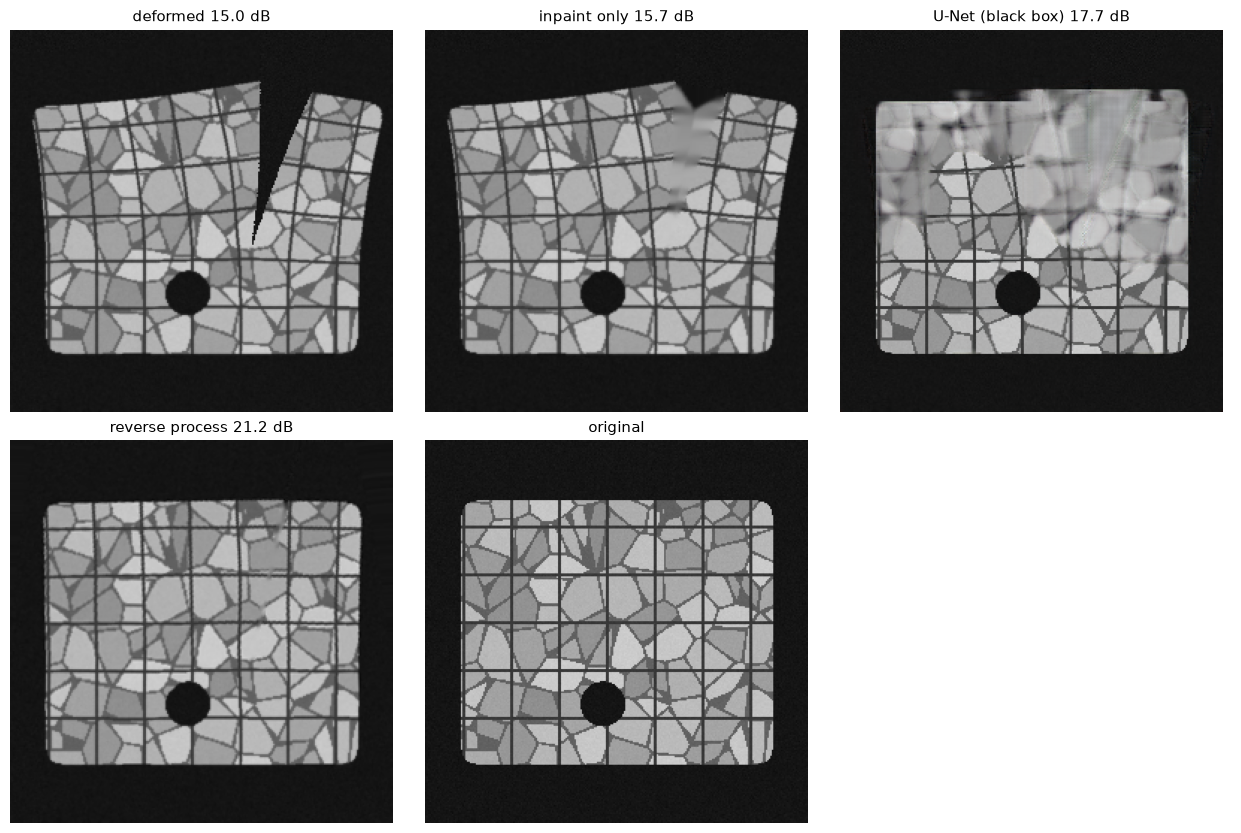

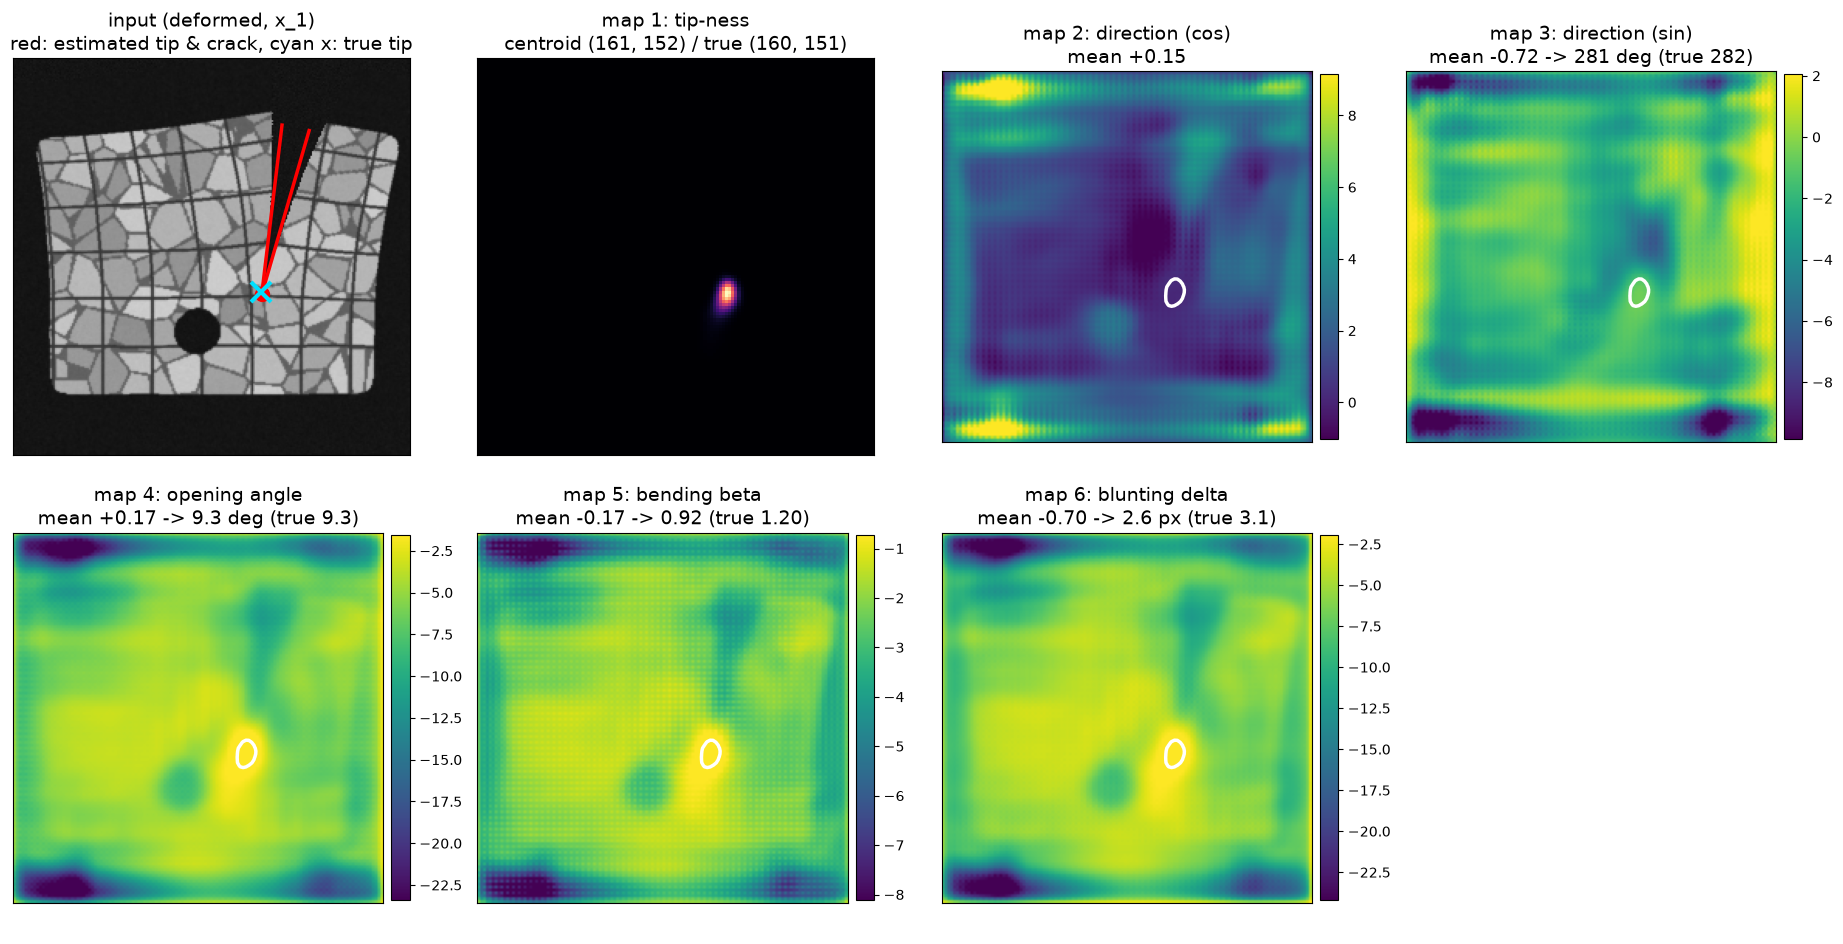

AI が読んだ 6 個の数：先端 (160.6, 152.4)、向き 281 度、開いた角度 9.3 度、曲がり β 0.92、鈍化 2.6 画素
地図 1 は先端の所だけが光り、その重心が先端の位置。地図 2〜6 は、白線（先端らしさの 90% が入る範囲）の中の値だけが使われる


In [9]:
def inpaint_ns(y, mask):
    u8 = (np.clip(y, 0, 1) * 255).astype(np.uint8)
    m8 = cv2.dilate(mask.astype(np.uint8), np.ones((3, 3), np.uint8))
    return cv2.inpaint(u8, m8 * 255, 3, cv2.INPAINT_NS).astype(np.float32) / 255

def outside(y):
    """外の背景とつながった暗い所"""
    lab, _ = ndimage.label(y[..., 0] < 0.15)
    border = np.unique(np.r_[lab[0], lab[-1], lab[:, 0], lab[:, -1]]); border = border[border > 0]
    return np.isin(lab, border)

def find_gap(y):
    """すき間：外の背景とつながった暗い所のうち、板の凸包の内側にあるもの（縁に沿った細い切れ端は除く）"""
    bg = outside(y)
    hull = np.zeros((S2, S2), np.uint8)
    cv2.fillPoly(hull, [cv2.convexHull(np.argwhere(~bg)[:, ::-1].astype(np.int32))], 1)
    hull = cv2.erode(hull, np.ones((5, 5), np.uint8))
    cand = (bg & (hull > 0)).astype(np.uint8)
    thick = cv2.morphologyEx(cand, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8)) > 0
    band = ~(cv2.erode(hull, np.ones((11, 11), np.uint8)) > 0)
    lab, n = ndimage.label(thick | (cand > 0) & ~band)
    return (lab == np.argmax(np.bincount(lab.ravel())[1:]) + 1) if n else cand > 0

def reverse(y, steps=3):
    """逆過程：今の画像から物理パラメータを推定し、残りの変形の 1/(残りの回数) だけ戻す（steps 回）"""
    M = GRID.copy(); x = y
    for k in range(steps):
        with torch.no_grad():
            p = phys_net(torch.from_numpy(x).permute(2, 0, 1)[None].to(DEVICE))
            fr = 1.0 / (steps - k)
            T = deform_t(p[0], p[1], p[2], p[3] * fr, p[4], p[5] * fr)[0].cpu().numpy()
        M = cv2.remap(M, T[..., 0], T[..., 1], cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)   # これまでの戻し方とつなげる
        x = cv2.remap(y, M[..., 0], M[..., 1], cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)    # 観測画像から 1 回で取り直す
    hole = cv2.remap(find_gap(y).astype(np.float32), M[..., 0], M[..., 1], cv2.INTER_LINEAR) > 0.3  # 閉じても残った細い割れ目
    return inpaint_ns(x, hole), M

def line_f(o, x, tol=1.5):
    """けがき線・粒界（暗い線）が正しい位置に戻ったか：F 値（1.5 画素以内なら正解、1 が満点）"""
    inner = cv2.erode((~outside(x)).astype(np.uint8), np.ones((5, 5), np.uint8)).astype(bool)
    gl, ol = (x[..., 0] < 0.45) & inner, (o[..., 0] < 0.45) & inner
    dg = cv2.distanceTransform((~gl).astype(np.uint8), cv2.DIST_L2, 3); do = cv2.distanceTransform((~ol).astype(np.uint8), cv2.DIST_L2, 3)
    pr = (dg[ol] <= tol).mean() if ol.any() else 0; rc = (do[gl] <= tol).mean()
    return 2 * pr * rc / max(pr + rc, 1e-6)

names2 = ["input (deformed)", "inpaint only", "U-Net image->image (black box)", "reverse process, 1 step", "reverse process, 3 steps", "true parameters (ref.)"]
res2 = {k: {m: [] for m in ("psnr", "ssim", "line")} for k in names2}
rng_e = np.random.default_rng(7)
for k in range(20):                                                          # 評価：学習に使っていない 20 枚（t = 1）
    x, hc = make_part(rng_e); pr = rand_params(rng_e, hc)
    y, _ = render(x, pr, 1.0, rng_e, ss=2); T = deform_map(pr, 1.0)
    true = inpaint_ns(cv2.remap(y, T[..., 0], T[..., 1], cv2.INTER_CUBIC), cv2.remap(find_gap(y).astype(np.float32), T[..., 0], T[..., 1], cv2.INTER_LINEAR) > 0.3)
    outs = [y, inpaint_ns(y, find_gap(y)), run_cnn(img_net, y), reverse(y, 1)[0], reverse(y, 3)[0], true]
    for name, o in zip(names2, outs):
        o = np.clip(o, 0, 1)
        res2[name]["psnr"].append(P(o, x)); res2[name]["ssim"].append(ssim(o, x)); res2[name]["line"].append(line_f(o, x))
    if k == 0:
        ex2 = (x, outs, pr)
for name in names2:
    m = {k: np.mean(v) for k, v in res2[name].items()}
    print(f"{name:32s} PSNR {m['psnr']:5.2f} dB   SSIM {m['ssim']:.3f}   線の F 値 {m['line']:.3f}")
x, outs, pr0 = ex2
show([outs[0], outs[1], outs[2], outs[4], x],
     [f"deformed {P(outs[0],x):.1f} dB", f"inpaint only {P(outs[1],x):.1f} dB", f"U-Net (black box) {P(outs[2],x):.1f} dB",
      f"reverse process {P(outs[4],x):.1f} dB", "original"], size=4.2, rows=2)

# AI の中身：U-Net が出す 6 枚の地図をすべて表示し、そこから読んだ 6 個の数を正解と比べる
y = outs[0]
with torch.no_grad():
    xt = torch.from_numpy(y).permute(2, 0, 1)[None].to(DEVICE)
    p = [v.item() for v in phys_net(xt)]
    o = phys_net.u(torch.cat([F.avg_pool2d(xt, 2), phys_net.coord], 1))[0].cpu().numpy()   # 6 × (S2/2) × (S2/2)
att = np.exp(o[0] - o[0].max()); att /= att.sum()                           # 地図 1 の softmax ＝ 先端らしさ
v = (o[1:].reshape(5, -1) * att.ravel()).sum(1)                             # 地図 2〜6 を、先端らしさで重み付けして平均
deg = lambda r: np.degrees(r) % 360
ext = (0, S2, S2, 0)                                                        # 地図は半分の大きさ → 元の画像の座標で表示
fig, axes = plt.subplots(2, 4, figsize=(18.5, 9.6)); ax = axes.ravel()
ax[0].imshow(np.clip(y, 0, 1), extent=ext)
for sg in (1, -1):                                                          # 推定した向き・開いた角度で、割れた面の向きを描く
    ang = p[2] + sg * p[3] / 2
    ax[0].plot([p[0], p[0] + 110 * np.cos(ang)], [p[1], p[1] + 110 * np.sin(ang)], "-", color="red", lw=2.5)
ax[0].plot(p[0], p[1], "o", color="red", ms=10); ax[0].plot(pr0["tip"][0], pr0["tip"][1], "x", color="#00E0FF", ms=14, mew=3)
ax[0].set_title("input (deformed, x_1)\nred: estimated tip & crack, cyan x: true tip", fontsize=14)
ax[1].imshow(att ** 0.5, cmap="magma", extent=ext)
ax[1].set_title(f"map 1: tip-ness\ncentroid ({p[0]:.0f}, {p[1]:.0f}) / true ({pr0['tip'][0]:.0f}, {pr0['tip'][1]:.0f})", fontsize=14)
rows_ = [("map 2: direction (cos)", f"mean {v[0]:+.2f}"),
         ("map 3: direction (sin)", f"mean {v[1]:+.2f} -> {deg(p[2]):.0f} deg (true {deg(pr0['a']):.0f})"),
         ("map 4: opening angle", f"mean {v[2]:+.2f} -> {np.degrees(p[3]):.1f} deg (true {np.degrees(pr0['theta']):.1f})"),
         ("map 5: bending beta", f"mean {v[3]:+.2f} -> {p[4]:.2f} (true {pr0['beta']:.2f})"),
         ("map 6: blunting delta", f"mean {v[4]:+.2f} -> {p[5]:.1f} px (true {pr0['delta']:.1f})")]
lev = np.sort(att.ravel())[::-1]; lev = lev[np.searchsorted(np.cumsum(lev), 0.9)]   # 先端らしさの 90% が入る範囲（白線）
n_ = S2 // 2; cc = np.linspace(1, S2 - 1, n_)
for k, (h, t_) in enumerate(rows_):
    m = o[k + 1]; lo, hi = np.percentile(m, [1, 99])
    im = ax[k + 2].imshow(m, cmap="viridis", vmin=lo, vmax=hi, extent=ext)
    ax[k + 2].contour(cc, cc, att, levels=[lev], colors="white", linewidths=2.5)
    fig.colorbar(im, ax=ax[k + 2], fraction=0.046, pad=0.02)
    ax[k + 2].set_title(h + "\n" + t_, fontsize=14)
ax[7].axis("off")
for a in ax[:7]:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()
print(f"AI が読んだ 6 個の数：先端 ({p[0]:.1f}, {p[1]:.1f})、向き {deg(p[2]):.0f} 度、開いた角度 {np.degrees(p[3]):.1f} 度、曲がり β {p[4]:.2f}、鈍化 {p[5]:.1f} 画素")
print("地図 1 は先端の所だけが光り、その重心が先端の位置。地図 2〜6 は、白線（先端らしさの 90% が入る範囲）の中の値だけが使われる")

**観察ポイント**：すき間を埋めるだけ（inpaint）では、広がった輪郭やけがき線・結晶粒のずれが残ります。
画像 → 画像 の U-Net は輪郭をほぼ戻しますが、**中の結晶粒の模様がぼけたり、作られたり** します（線の F 値が入力と変わらない）。
逆過程は、AI が出すのは物理パラメータだけで、画素は観測から持ってくるので、**模様は鮮明なまま、線が正しい位置に戻ります**。
残る誤差の多くは、物理モデルに入れていない「不均一なゆがみ」（最大 3 画素）によるもので、PSNR が正解のパラメータの場合ほど高くならない理由です。

**もう一つの方法（この演習では実装していない）**：一般的な拡散モデル（ノイズから画像を生成する）の逆過程の各ステップで、
「生成途中の画像を物理モデルで変形させると観測に一致する」ように誘導する（Diffusion Posterior Sampling：Chung+, ICLR 2023。
変形のパラメータが未知なら同時に推定する BlindDPS など）。結晶粒の見え方を大量の画像で学習した拡散モデルが必要で、
すき間の中身を「描く」ので、もっともらしいが本物でない模様（ハルシネーション）が入る可能性があります。

## まとめ
- 物理モデルを AI に組み込む方法はいくつもある：① 物理モデルで学習データを作る ② AI の計算の中に物理の式を入れる（Deep Unfolding）
  ③ AI には物理パラメータだけを出させ、復元は物理の式で行う ④ 物理の式を損失に入れる（PINN）
- スマホ → 一眼：劣化モデルのパラメータ（F 値・画素ピッチ・収差・光子数・読み出しノイズ）は、**仕様とチャートの撮影** で測れる。
  物理モデルを組み込んだ AI は、機材が変わってもパラメータを入れ替えるだけで対応でき、AI だけの方法より学習外の機材で大きく良い
- 塑性変形：変形の過程を物理モデルで作って順過程とし、拡散モデルの考え方で逆過程を学習できる。AI が出すのはパラメータだけなので模様を描かない
- 物理モデルが現実と合わない（モデルにない変形・ノイズ）と、その分は戻らない。モデルの前提をスライド・報告書に明記する